# K-Means transaccional de clientes Samsung — Python

### Análisis sobre TRAIN de la cohorte Pogit, sin variables de encuesta

Este notebook se adapta a la matriz `data/matrices/matrices_data{TAG}.csv` (hoja/matriz W_train), generada por R a partir de compras Amazon en T1. Usa **únicamente W**. No requiere matrices V, respuestas Y ni archivos TEST. Conserva `response_id` como identificador, nunca como variable de entrada a K-Means.

**Objetivos:** comparar 3, 4 y 6 variables transaccionales, explorar $K=2,\ldots,10$, revisar redundancia mediante Spearman, calcular calidad interna y estabilidad por remuestreo, elegir un modelo de forma documentada, caracterizar los segmentos en unidades originales de W y exportar la pertenencia de cada cliente.

**Preprocesamiento heredado de R (no repetir):** cohorte y división TRAIN/TEST de Pogit, filtro monetario T1 (`MIN_MONETARY_T1`, identificado por el TAG), exclusión severa T2 según la regla de la tesis, winsorización superior Tukey $k=3$ calculada con TRAIN. El CSV contiene W **antes de selección de predictores y escalado final de Pogit**. Este notebook únicamente estandariza para K-Means con TRAIN (desviación estándar muestral, `ddof=1`, compatible con `scale()` de R); no aplica una nueva winsorización ni `log1p`.

El número $K=4$ y el conjunto de cuatro variables se usarán **como referencia inicial, no como ganadores predeterminados**. Lee las métricas y el diagnóstico de estabilidad antes de cerrar la decisión para la tesis.

## 0. Dependencias y configuración

Requiere `pandas`, `numpy`, `matplotlib`, `scipy` y `scikit-learn`. Si hace falta instalar: `pip install pandas numpy matplotlib scipy scikit-learn`.

Las matrices de entrada (W y V de TRAIN) se leen de `data/matrices/matrices_data{TAG}.csv` (si no existe el `.csv`, usa el `.xlsx` del mismo nombre) y el **TAG** (`TAG = f"_min{MIN_MONETARY_T1}"`, definido en `config_matrices.py`) discrimina el umbral `MIN_MONETARY_T1`: cambia el umbral allí y todo el flujo apunta a `matrices_data{TAG}` y a carpetas de resultados con ese TAG. Si está en otra ubicación, modifica `RUTA_CSV_MANUAL`. Las salidas se crean en `CARPETA_SALIDA` (no en `data/matrices`), en subcarpetas con el TAG.

In [1]:
from pathlib import Path
from config_matrices import MIN_MONETARY_T1, TAG, CARPETA_SALIDA, ruta_matrices, cargar_W_train
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

SEMILLA = 123
K_VALORES = range(2, 11)
N_INIT = 30
MIN_PROP_ALERTA = 0.03  # criterio descriptivo; no implica descartar automáticamente
N_REMUESTREOS = 100  # estabilidad: subsampling 80% de TRAIN, sin reemplazo
FRACCION_REMUESTREO = 0.80

# Matrices de entrada (W y V de TRAIN): data/matrices/matrices_data{TAG}; el TAG discrimina MIN_MONETARY_T1
RUTA_CSV_MANUAL = f"../../data/matrices/matrices_data{TAG}.csv"
RUTA_CSV = ruta_matrices(RUTA_CSV_MANUAL)
SALIDAS = CARPETA_SALIDA / f"resultados_kmeans_python{TAG}"
SALIDAS.mkdir(parents=True, exist_ok=True)
print("MIN_MONETARY_T1:", MIN_MONETARY_T1, "| TAG:", TAG)
print("Datos:", RUTA_CSV)
print("Resultados:", SALIDAS)
print("Módulo sklearn cargado; semilla:", SEMILLA)

MIN_MONETARY_T1: 80 | TAG: _min80
Datos: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\data\Matrices\matrices_data_min80.xlsx
Resultados: c:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_kmeans_python_min80
Módulo sklearn cargado; semilla: 123


## 1. Importar y auditar `response_id` y las variables

El CSV de TRAIN debe tener una fila por cliente. Los valores de las variables son los ya winsorizados de T1, no necesariamente los importes transaccionales crudos. No se recalcula el ratio: en R se calculó **antes** de winsorizar cada columna.

In [2]:
df = cargar_W_train(RUTA_CSV)
if "response_id" not in df.columns:
    raise ValueError("El CSV debe contener response_id")
df["response_id"] = df["response_id"].str.strip()
if df["response_id"].isna().any() or df["response_id"].eq("").any():
    raise ValueError("Hay identificadores vacíos")
if df["response_id"].duplicated().any():
    raise ValueError("Hay response_id duplicados")

RFM = [
    "recency_days_2018_Samsung",
    "frequency_2018_Samsung",
    "monetary_2018_Samsung",
]
SEIS_VARIABLES = RFM + [
    "dollar_avg_12m",
    "dollar_top1_12m",
    "dollar_avg12_top1_ratio",
]
CONFIGURACIONES = {
    "A_RFM_3": RFM,
    "B_RFM_ratio_4": RFM + ["dollar_avg12_top1_ratio"],
    "C_W_6": SEIS_VARIABLES,
}

faltantes = [v for v in SEIS_VARIABLES if v not in df.columns]
if faltantes:
    raise ValueError(f"El CSV no contiene estas variables: {faltantes}")
for variable in SEIS_VARIABLES:
    df[variable] = pd.to_numeric(df[variable], errors="raise")
if not np.isfinite(df[SEIS_VARIABLES].to_numpy(dtype=float)).all():
    raise ValueError("Las seis variables deben ser finitas y sin NA")
if (df[SEIS_VARIABLES].std(ddof=1) == 0).any():
    raise ValueError("Alguna de las seis variables tiene varianza cero")

print(f"Clientes TRAIN: {len(df):,}")
print(f"Columnas disponibles: {df.shape[1]}")
print("ID único:", df.response_id.is_unique)
print("Configuraciones:", {k: len(v) for k, v in CONFIGURACIONES.items()})
display(df[["response_id"] + SEIS_VARIABLES].head())

auditoria = pd.DataFrame({
    "variable": SEIS_VARIABLES,
    "faltantes": [int(df[v].isna().sum()) for v in SEIS_VARIABLES],
    "n_ceros": [int((df[v] == 0).sum()) for v in SEIS_VARIABLES],
    "min": [float(df[v].min()) for v in SEIS_VARIABLES],
    "max": [float(df[v].max()) for v in SEIS_VARIABLES],
})
display(auditoria)
auditoria.to_csv(SALIDAS / "auditoria_variables_W.csv", index=False)

Clientes TRAIN: 1,752
Columnas disponibles: 7
ID único: True
Configuraciones: {'A_RFM_3': 3, 'B_RFM_ratio_4': 4, 'C_W_6': 6}


C:\Users\jeam2\AppData\Local\Temp\ipykernel_22088\381448227.py:1: UserWarning: La matriz no trae 'response_id': se crea un identificador por posición (train_00001, ...). Sirve para K-Means, pero NO permite cruzar con otras tablas; el orden de filas debe ser el de train_ids.
  df = cargar_W_train(RUTA_CSV)


,response_id,recency_days_2018_Samsung,frequency_2018_Samsung,monetary_2018_Samsung,dollar_avg_12m,dollar_top1_12m,dollar_avg12_top1_ratio
0,train_00001,-1.089655,3.019810,2.811424,2.505323,2.485585,0.815658
1,train_00002,-0.521122,1.590533,-0.197344,0.388149,0.282259,1.151924
2,train_00003,-0.767948,-0.315170,-0.651248,-0.110252,0.041881,0.510317
3,train_00004,0.113971,-0.315170,-0.215876,-0.653847,-0.673430,-0.965571
4,train_00005,-0.826188,-0.315170,-0.485667,-0.369724,-0.299555,0.510317


,variable,faltantes,n_ceros,min,max
0,recency_days_2018_Samsung,0,0,-1.203361,2.670982
1,frequency_2018_Samsung,0,0,-0.791595,3.019810
2,monetary_2018_Samsung,0,0,-0.796713,2.811424
3,dollar_avg_12m,0,0,-0.653847,2.505323
4,dollar_top1_12m,0,0,-0.673430,2.485585
5,dollar_avg12_top1_ratio,0,0,-0.965571,4.605001


## 2. Diagnóstico de redundancia — Spearman

Se estudian las seis variables, aunque una configuración utilice solo tres o cuatro. Correlaciones altas son una señal de redundancia posible, no una orden automática para eliminar predictores. En particular, `dollar_avg_12m`, `dollar_top1_12m` y su ratio pueden estar fuertemente relacionados; la estandarización no elimina esa redundancia.

Resumen de variables winsorizadas (unidades de W):


,count,mean,std,min,25%,50%,75%,max
variable,,,,,,,,
recency_days_2018_Samsung,1752.0,-0.0,1.0,-1.203,-0.821,-0.310,0.669,2.671
frequency_2018_Samsung,1752.0,-0.0,1.0,-0.792,-0.792,-0.315,0.161,3.020
monetary_2018_Samsung,1752.0,0.0,1.0,-0.797,-0.653,-0.458,0.213,2.811
dollar_avg_12m,1752.0,0.0,1.0,-0.654,-0.654,-0.405,0.136,2.505
dollar_top1_12m,1752.0,0.0,1.0,-0.673,-0.673,-0.359,0.116,2.486
dollar_avg12_top1_ratio,1752.0,-0.0,1.0,-0.966,-0.966,0.510,0.510,4.605


Matriz Spearman:


,recency_days_2018_Samsung,frequency_2018_Samsung,monetary_2018_Samsung,dollar_avg_12m,dollar_top1_12m,dollar_avg12_top1_ratio
recency_days_2018_Samsung,1.000,-0.441,-0.260,-0.804,-0.790,-0.858
frequency_2018_Samsung,-0.441,1.000,0.651,0.435,0.406,0.479
monetary_2018_Samsung,-0.260,0.651,1.000,0.414,0.403,0.297
dollar_avg_12m,-0.804,0.435,0.414,1.000,0.992,0.917
dollar_top1_12m,-0.790,0.406,0.403,0.992,1.000,0.882
dollar_avg12_top1_ratio,-0.858,0.479,0.297,0.917,0.882,1.000


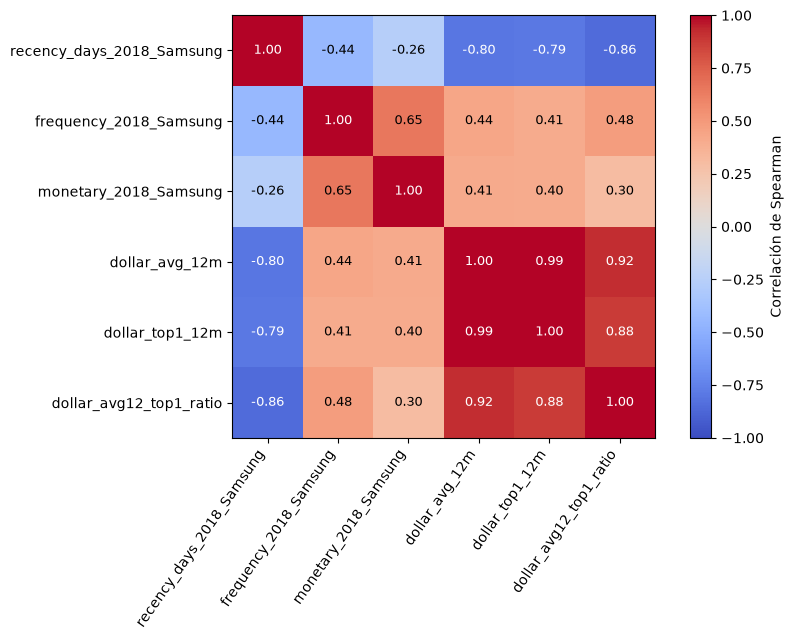

In [3]:
resumen_W = df[SEIS_VARIABLES].describe(percentiles=[.25, .5, .75]).T
resumen_W.index.name = "variable"
cor_spearman = df[SEIS_VARIABLES].corr(method="spearman")
print("Resumen de variables winsorizadas (unidades de W):")
display(resumen_W.round(3))
print("Matriz Spearman:")
display(cor_spearman.round(3))
resumen_W.to_csv(SALIDAS / "resumen_variables_W.csv")
cor_spearman.to_csv(SALIDAS / "correlacion_spearman.csv")

fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(cor_spearman.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(SEIS_VARIABLES)), SEIS_VARIABLES, rotation=55, ha="right")
ax.set_yticks(range(len(SEIS_VARIABLES)), SEIS_VARIABLES)
for i in range(len(SEIS_VARIABLES)):
    for j in range(len(SEIS_VARIABLES)):
        x = cor_spearman.iloc[i, j]
        ax.text(j, i, f"{x:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(x) > .70 else "black")
fig.colorbar(im, ax=ax, label="Correlación de Spearman")
fig.tight_layout()
fig.savefig(SALIDAS / "correlacion_spearman.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Escalado por configuración (solo TRAIN)

La matriz W ya viene winsorizada en R. Se calcula $z=(x-\bar{x}_{TRAIN})/s_{TRAIN}$ con $s$ muestral (`ddof=1`) para igualar el convenio de `scale()` en R. No se introduce información TEST ni variables de encuesta. Se guardan los parámetros de escalado para reproducibilidad.

In [4]:
def estandarizar_train(df_entrada, variables):
    crudo = df_entrada[variables].to_numpy(dtype=float)
    medias = crudo.mean(axis=0)
    desv = crudo.std(axis=0, ddof=1)
    if np.any(desv <= 0) or not np.isfinite(desv).all():
        raise ValueError("Se encontró alguna desviación estándar no válida")
    z = (crudo - medias) / desv
    return z, pd.DataFrame({
        "variable": variables, "media_train": medias, "sd_train_ddof1": desv
    })

datos_escalados = {}
parametros = []
for nombre, variables in CONFIGURACIONES.items():
    z, p = estandarizar_train(df, variables)
    datos_escalados[nombre] = z
    p.insert(0, "configuracion", nombre)
    parametros.append(p)
parametros_escalado = pd.concat(parametros, ignore_index=True)
parametros_escalado.to_csv(SALIDAS / "parametros_escalado_train.csv", index=False)
print("Dimensiones por configuración:", {k: v.shape for k, v in datos_escalados.items()})
display(parametros_escalado.round(4))

Dimensiones por configuración: {'A_RFM_3': (1752, 3), 'B_RFM_ratio_4': (1752, 4), 'C_W_6': (1752, 6)}


,configuracion,variable,media_train,sd_train_ddof1
0,A_RFM_3,recency_days_2018_Samsung,-0.0,1.0
1,A_RFM_3,frequency_2018_Samsung,-0.0,1.0
2,A_RFM_3,monetary_2018_Samsung,0.0,1.0
3,B_RFM_ratio_4,recency_days_2018_Samsung,-0.0,1.0
4,B_RFM_ratio_4,frequency_2018_Samsung,-0.0,1.0
5,B_RFM_ratio_4,monetary_2018_Samsung,0.0,1.0
6,B_RFM_ratio_4,dollar_avg12_top1_ratio,-0.0,1.0
7,C_W_6,recency_days_2018_Samsung,-0.0,1.0
8,C_W_6,frequency_2018_Samsung,-0.0,1.0
9,C_W_6,monetary_2018_Samsung,0.0,1.0


## 4. Exploración de K-Means: $K=2,\ldots,10$

Para cada configuración se calculan inercia, silueta euclidiana, Calinski–Harabasz, Davies–Bouldin, tamaños y equilibrio. Todas las métricas, incluida la **silueta euclidiana exacta**, se calculan sobre la totalidad de TRAIN. El ajuste de K-Means también utiliza TRAIN completo. No compares directamente inercias entre configuraciones de diferente dimensionalidad. Un grupo con menos de 3 % de TRAIN se marca como **alerta**, no se elimina automáticamente.

In [5]:
def metricas_de_agrupamiento(X, etiquetas):
    k_real = len(np.unique(etiquetas))
    if k_real < 2 or k_real >= len(etiquetas):
        return dict(silhouette_euclidean=np.nan, calinski_harabasz=np.nan, davies_bouldin=np.nan)
    return {
        "silhouette_euclidean": float(silhouette_score(X, etiquetas)),
        "calinski_harabasz": float(calinski_harabasz_score(X, etiquetas)),
        "davies_bouldin": float(davies_bouldin_score(X, etiquetas)),
    }

resultados_exploracion = []
modelos_grid = {}
N = len(df)
for nombre, X in datos_escalados.items():
    for k in K_VALORES:
        if k >= N:
            continue
        modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=N_INIT, max_iter=400)
        etiquetas = modelo.fit_predict(X)
        tamanos = np.bincount(etiquetas, minlength=k)
        k_real = int(np.sum(tamanos > 0))
        met = metricas_de_agrupamiento(X, etiquetas)
        resultados_exploracion.append({
            "configuracion": nombre,
            "n_variables": len(CONFIGURACIONES[nombre]),
            "k": k,
            "n_clusters_reales": k_real,
            "min_cluster": int(tamanos[tamanos > 0].min()),
            "max_cluster": int(tamanos.max()),
            "balance_ratio": float(tamanos[tamanos > 0].min() / tamanos.max()),
            "min_cluster_pct": float(100 * tamanos[tamanos > 0].min() / N),
            "alerta_cluster_menor_3pct": bool((tamanos > 0).any() and tamanos[tamanos > 0].min() / N < MIN_PROP_ALERTA),
            "cluster_sizes": ";".join(map(str, tamanos)),
            "inercia": float(modelo.inertia_),
            **met,
        })
        modelos_grid[(nombre, k)] = modelo
exploracion = pd.DataFrame(resultados_exploracion).sort_values(["configuracion", "k"])
exploracion.to_csv(SALIDAS / "exploracion_A_B_C_k2_k10.csv", index=False)
display(exploracion.round(4))

,configuracion,n_variables,k,n_clusters_reales,min_cluster,max_cluster,balance_ratio,min_cluster_pct,alerta_cluster_menor_3pct,cluster_sizes,inercia,silhouette_euclidean,calinski_harabasz,davies_bouldin
0,A_RFM_3,3,2,2,402,1350,0.2978,22.9452,False,1350;402,3207.9219,0.4465,1115.6402,1.0698
1,A_RFM_3,3,3,3,336,918,0.3660,19.1781,False,918;498;336,2092.6833,0.4040,1320.6475,0.9247
2,A_RFM_3,3,4,4,167,896,0.1864,9.5320,False,211;478;896;167,1606.7839,0.4236,1322.2242,0.9192
3,A_RFM_3,3,5,5,111,748,0.1484,6.3356,False,748;111;296;451;146,1258.0734,0.4101,1386.8700,0.8498
4,A_RFM_3,3,6,6,111,547,0.2029,6.3356,False,290;111;415;547;141;248,1057.9522,0.3705,1384.6662,0.8758
5,A_RFM_3,3,7,7,88,434,0.2028,5.0228,False,434;122;382;135;355;88;236,918.9875,0.3649,1371.5914,0.8787
6,A_RFM_3,3,8,8,88,409,0.2152,5.0228,False,101;358;292;135;88;242;409;127,815.8272,0.3763,1355.0541,0.9184
7,A_RFM_3,3,9,9,69,404,0.1708,3.9384,False,292;356;88;79;404;128;69;212;124,722.2642,0.3888,1366.7216,0.8554
8,A_RFM_3,3,10,10,64,398,0.1608,3.6530,False,114;79;236;91;214;114;64;398;314;128,647.6053,0.4003,1376.4552,0.8293
9,B_RFM_ratio_4,4,2,2,795,957,0.8307,45.3767,False,957;795,4122.0780,0.4168,1223.5003,1.0203


## 4A. Método del codo — WSS / inercia frente a K

Este gráfico reproduce el formato del ejemplo aportado: eje horizontal con el número de clústeres, eje vertical con la suma de cuadrados dentro de clústeres (**WSS**, o `inertia_` de `KMeans`). **Se calcula exclusivamente sobre TRAIN**, con las variables de W previamente winsorizadas en R y estandarizadas en Python. No se utilizan las respuestas de encuesta ni información de TEST.

- Para **K = 1**, la WSS corresponde a la suma de cuadrados con respecto a una única media global, calculada sin volver a ajustar los modelos exploratorios.
- Para **K = 2,...,10**, se reutilizan las inercias ya obtenidas en `exploracion`.
- El punto naranja es una **estimación geométrica** del codo: máxima distancia a la recta que une los extremos de la curva normalizada. Es un criterio orientativo, **no** una selección automática del K definitivo.
- Se genera una figura independiente para las configuraciones A (3 variables), B (4 variables) y C (6 variables). No conviene comparar los valores absolutos de WSS entre configuraciones de distinta dimensionalidad.

En B se marca además **K = 4 como referencia** para cotejarlo con Silhouette y estabilidad, aunque la regla geométrica pueda sugerir K = 3. La elección final del número de grupos debe considerar todos los diagnósticos.

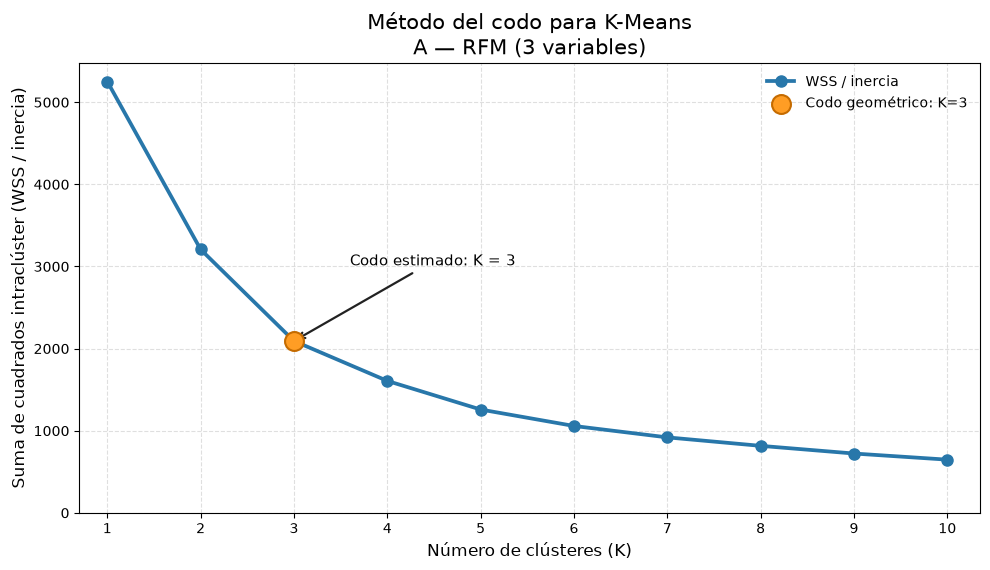

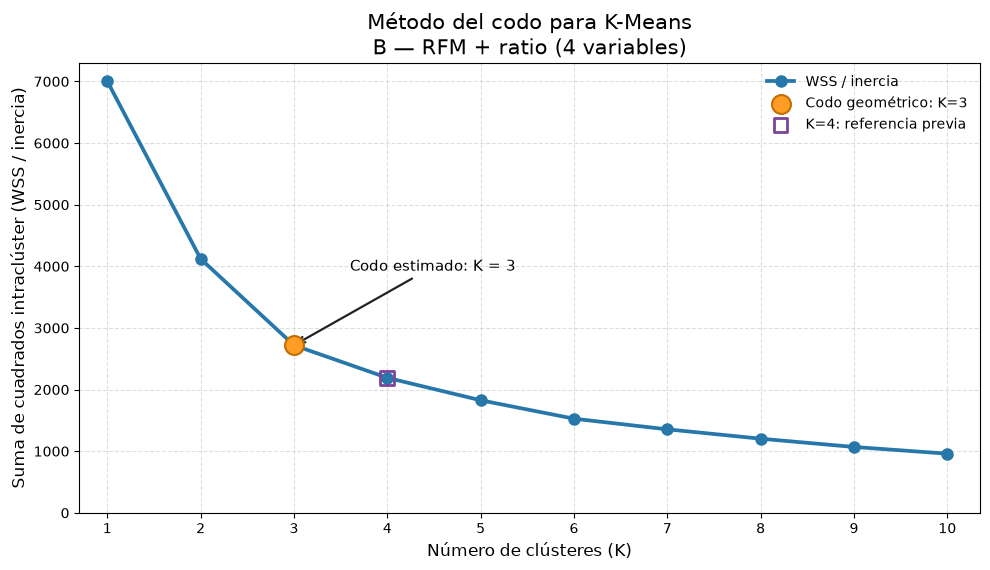

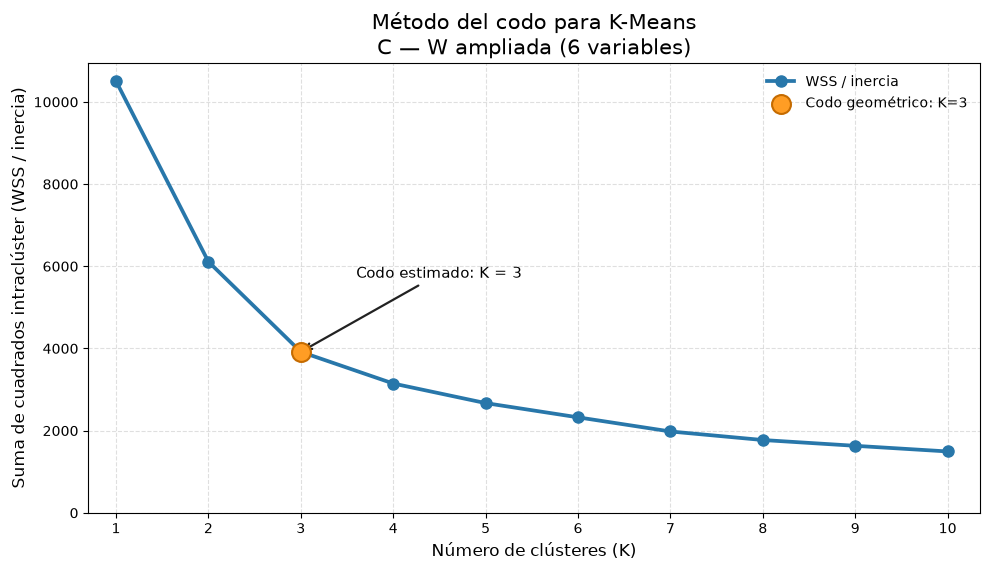

,configuracion,n_variables,k_codo_geometrico,wss_k1,wss_en_codo,grafico
0,A_RFM_3,3,3,5253.0,2092.683266,grafico_codo_A_RFM_3.png
1,B_RFM_ratio_4,4,3,7004.0,2719.707221,grafico_codo_B_RFM_ratio_4.png
2,C_W_6,6,3,10506.0,3918.054226,grafico_codo_C_W_6.png


In [6]:
# Curvas de codo para A (3), B (4) y C (6) variables.
# Requiere ejecutar las celdas anteriores (datos_escalados y exploracion).

def codo_geometrico(k_valores, wss):
    """K interior con máxima distancia a la cuerda en coordenadas normalizadas."""
    k_valores = np.asarray(k_valores, dtype=float)
    wss = np.asarray(wss, dtype=float)
    x = (k_valores - k_valores.min()) / (k_valores.max() - k_valores.min())
    y = (wss - wss.min()) / (wss.max() - wss.min())
    puntos = np.column_stack([x, y])
    a, b = puntos[0], puntos[-1]
    vector = b - a
    distancias = np.abs(vector[0] * (puntos[:, 1] - a[1]) -
                        vector[1] * (puntos[:, 0] - a[0])) / np.linalg.norm(vector)
    return int(k_valores[1:-1][np.argmax(distancias[1:-1])])

nombres_grafico = {
    "A_RFM_3": "A — RFM (3 variables)",
    "B_RFM_ratio_4": "B — RFM + ratio (4 variables)",
    "C_W_6": "C — W ampliada (6 variables)",
}
resultados_codo = []

for configuracion, nombre_legible in nombres_grafico.items():
    X = datos_escalados[configuracion]
    # Inercia de K=1: suma de cuadrados al centroide global de TRAIN.
    wss_k1 = float(((X - X.mean(axis=0)) ** 2).sum())
    sub = exploracion.loc[
        exploracion["configuracion"] == configuracion,
        ["k", "inercia"]
    ].sort_values("k")
    k_valores = np.r_[1, sub["k"].to_numpy(dtype=int)]
    wss = np.r_[wss_k1, sub["inercia"].to_numpy(dtype=float)]
    k_codo = codo_geometrico(k_valores, wss)
    wss_codo = float(wss[np.where(k_valores == k_codo)[0][0]])

    fig, ax = plt.subplots(figsize=(10, 5.8))
    ax.plot(k_valores, wss, color="#2877aa", linewidth=2.7,
            marker="o", markersize=8, label="WSS / inercia")
    ax.scatter([k_codo], [wss_codo], s=185, color="#ff9d24",
               edgecolor="#c56b00", linewidth=1.5, zorder=5,
               label=f"Codo geométrico: K={k_codo}")
    ax.annotate(f"Codo estimado: K = {k_codo}",
                xy=(k_codo, wss_codo),
                xytext=(k_codo + 0.6, wss_codo + 0.20 * (wss.max() - wss.min())),
                arrowprops=dict(arrowstyle="->", linewidth=1.6, color="#222222"),
                fontsize=11)
    if configuracion == "B_RFM_ratio_4":
        wss_k4 = float(wss[np.where(k_valores == 4)[0][0]])
        ax.scatter([4], [wss_k4], marker="s", s=100,
                   facecolors="none", edgecolors="#7b449b", linewidths=2,
                   zorder=6, label="K=4: referencia previa")
    ax.set_title(f"Método del codo para K-Means\n{nombre_legible}", fontsize=15)
    ax.set_xlabel("Número de clústeres (K)", fontsize=12)
    ax.set_ylabel("Suma de cuadrados intraclúster (WSS / inercia)", fontsize=12)
    ax.set_xticks(k_valores)
    ax.set_xlim(0.7, 10.35)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle="--", alpha=.40)
    ax.legend(loc="upper right", frameon=False)
    fig.tight_layout()
    ruta_fig = SALIDAS / f"grafico_codo_{configuracion}.png"
    fig.savefig(ruta_fig, dpi=190, bbox_inches="tight")
    plt.show()

    resultados_codo.append({
        "configuracion": configuracion,
        "n_variables": X.shape[1],
        "k_codo_geometrico": k_codo,
        "wss_k1": wss_k1,
        "wss_en_codo": wss_codo,
        "grafico": ruta_fig.name,
    })

tabla_codos = pd.DataFrame(resultados_codo)
tabla_codos.to_csv(SALIDAS / "resumen_metodo_codo.csv", index=False)
display(tabla_codos)


## 5. Visualizar la calidad de las configuraciones

Silueta y Calinski–Harabasz: mayor suele ser mejor; Davies–Bouldin: menor suele ser mejor. Los tamaños y la estabilidad también importan. La solución de referencia $K=4$ se señala solo para comparación.

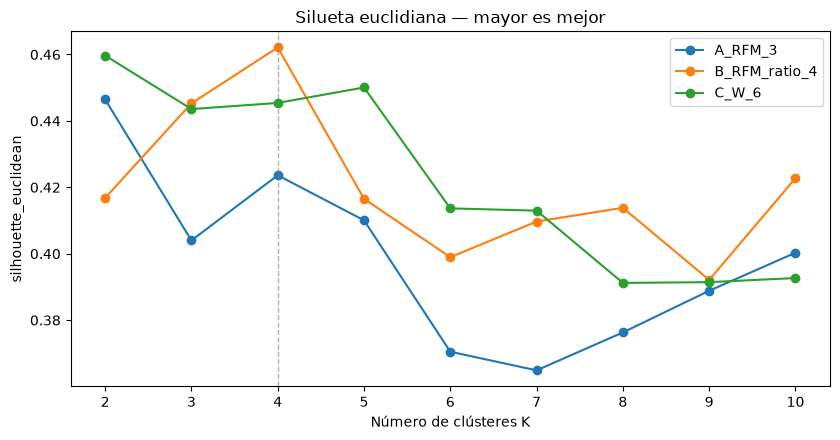

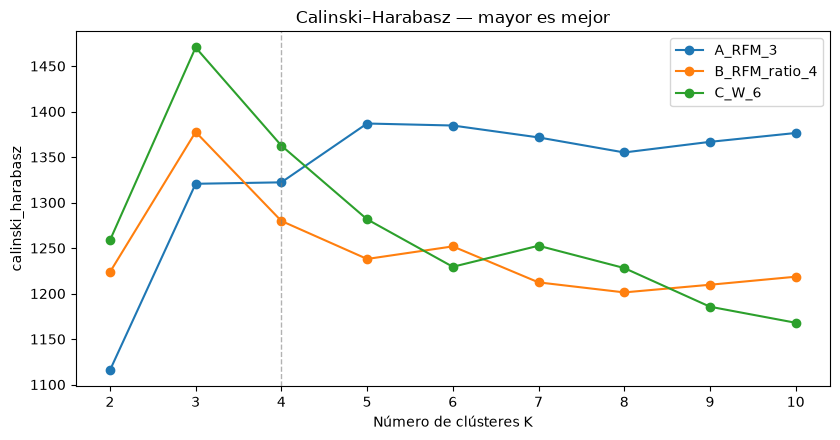

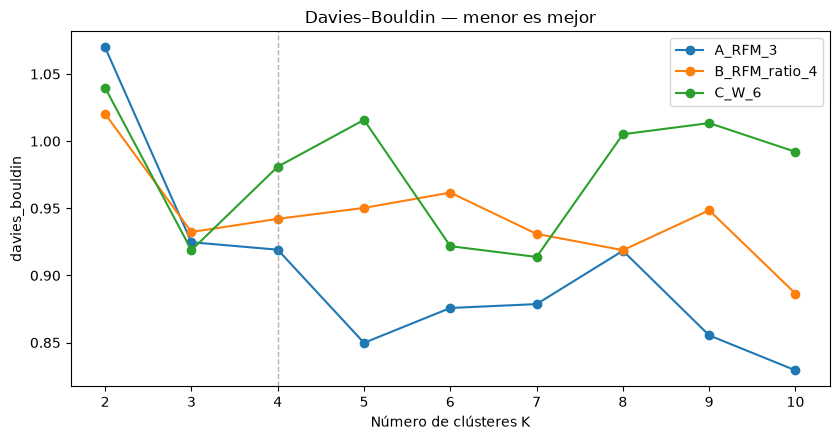

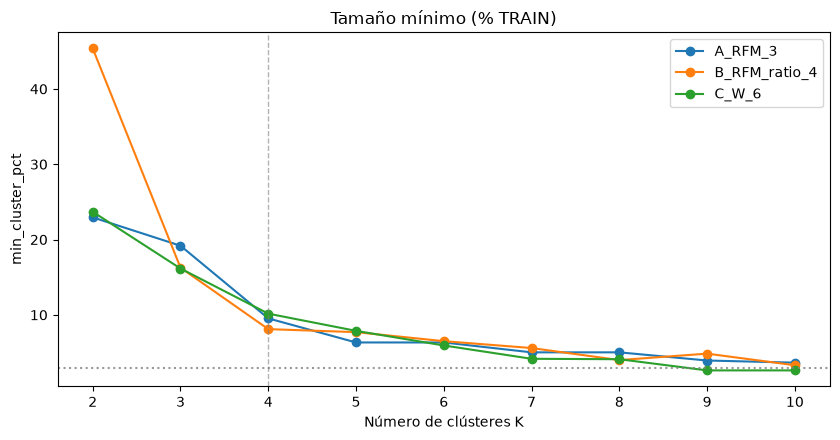

In [7]:
metricas_graficas = [
    ("silhouette_euclidean", "Silueta euclidiana — mayor es mejor"),
    ("calinski_harabasz", "Calinski–Harabasz — mayor es mejor"),
    ("davies_bouldin", "Davies–Bouldin — menor es mejor"),
    ("min_cluster_pct", "Tamaño mínimo (% TRAIN)"),
]
for columna, titulo in metricas_graficas:
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    for nombre, grupo in exploracion.groupby("configuracion", sort=False):
        ax.plot(grupo["k"], grupo[columna], marker="o", label=nombre)
    ax.axvline(4, linestyle="--", linewidth=1, color="gray", alpha=.6)
    if columna == "min_cluster_pct":
        ax.axhline(100 * MIN_PROP_ALERTA, linestyle=":", color="gray", alpha=.8)
    ax.set(xlabel="Número de clústeres K", ylabel=columna, title=titulo)
    ax.legend()
    fig.tight_layout()
    fig.savefig(SALIDAS / f"grafico_{columna}.png", dpi=180, bbox_inches="tight")
    plt.show()

## 6. Selección de candidatos para analizar estabilidad

Se evalúa el candidato con mayor silueta **entre las soluciones sin alertas de grupos pequeños** de cada configuración; si ninguna cumple, se considera la de mayor silueta y se advierte el problema. Se incluye adicionalmente `B_RFM_ratio_4` con $K=4$ como referencia, si no quedó elegida. Este procedimiento **solo construye una lista corta**, no selecciona automáticamente la solución definitiva.

In [8]:
candidatos = []
for configuracion, grupo in exploracion.groupby("configuracion", sort=False):
    elegibles = grupo.loc[
        (grupo.n_clusters_reales == grupo.k) & ~grupo.alerta_cluster_menor_3pct
    ]
    if elegibles.empty:
        warnings.warn(f"{configuracion}: ninguna solución cumple la alerta del 3%; se revisará la de mayor silueta")
        elegibles = grupo.loc[grupo.n_clusters_reales == grupo.k]
    mejor = elegibles.sort_values("silhouette_euclidean", ascending=False).iloc[0]
    candidatos.append((str(mejor.configuracion), int(mejor.k)))

REFERENCIA = ("B_RFM_ratio_4", 4)
if REFERENCIA in modelos_grid and REFERENCIA not in candidatos:
    candidatos.append(REFERENCIA)
candidatos = list(dict.fromkeys(candidatos))
tabla_candidatos = exploracion.set_index(["configuracion", "k"]).loc[candidatos].reset_index()
print("Candidatos de estabilidad:", candidatos)
display(tabla_candidatos.round(4))

Candidatos de estabilidad: [('A_RFM_3', 2), ('B_RFM_ratio_4', 4), ('C_W_6', 2)]


,configuracion,k,n_variables,n_clusters_reales,min_cluster,max_cluster,balance_ratio,min_cluster_pct,alerta_cluster_menor_3pct,cluster_sizes,inercia,silhouette_euclidean,calinski_harabasz,davies_bouldin
0,A_RFM_3,2,3,2,402,1350,0.2978,22.9452,False,1350;402,3207.9219,0.4465,1115.6402,1.0698
1,B_RFM_ratio_4,4,4,4,142,732,0.1940,8.1050,False,672;142;732;206,2191.1774,0.4621,1279.8011,0.9421
2,C_W_6,2,6,2,415,1337,0.3104,23.6872,False,415;1337,6111.3972,0.4597,1258.3955,1.0398


## 7. Estabilidad por remuestreo: ARI y Jaccard por clúster

Para cada candidato, se extrae en cada repetición el 80 % de TRAIN **sin reemplazo**, se reajusta K-Means con las mismas variables/escalado de TRAIN y se compara su partición con la asignación del modelo de referencia **sobre los mismos clientes muestreados**.

- **ARI:** acuerdo global de particiones, invariante a permutación de etiquetas. Un ARI elevado indica estabilidad de asignaciones.
- **Jaccard por clúster:** se emparejan grupos mediante el algoritmo húngaro para maximizar la suma de sus Jaccard, comparando los miembros dentro de la misma submuestra. Se reportan media y desviación por grupo, además del mínimo entre las medias de los grupos.

Este es un diagnóstico de **submuestreo (sin reemplazo)**, no una validación supervisada ni una estimación de estabilidad mediante bootstrap clásico. Ejecutar las 100 repeticiones puede requerir tiempo. Se ajusta K-Means nuevamente en cada submuestra con la semilla correspondiente.

In [9]:
def jaccard_emparejado(etiquetas_ref, etiquetas_nuevas, k):
    """Jaccard por grupo original: emparejamiento óptimo por Hungarian, mismo conjunto de IDs."""
    matriz = np.zeros((k, k), dtype=float)
    for i in range(k):
        ref = etiquetas_ref == i
        for j in range(k):
            nuevo = etiquetas_nuevas == j
            union = np.count_nonzero(ref | nuevo)
            matriz[i, j] = (np.count_nonzero(ref & nuevo) / union) if union else 0.0
    filas, columnas = linear_sum_assignment(-matriz)
    salida = np.zeros(k, dtype=float)
    salida[filas] = matriz[filas, columnas]
    return salida

def medir_estabilidad(nombre, k, indice_candidato):
    X = datos_escalados[nombre]
    referencia = modelos_grid[(nombre, k)].labels_
    rng = np.random.default_rng(SEMILLA + 1000 * (indice_candidato + 1))
    n_sub = max(k + 1, int(np.floor(FRACCION_REMUESTREO * len(X))))
    resultados = []
    for rep in range(N_REMUESTREOS):
        ids_pos = rng.choice(len(X), size=n_sub, replace=False)
        nuevo = KMeans(
            n_clusters=k, n_init=N_INIT, random_state=SEMILLA + rep + 1,
            max_iter=400
        ).fit_predict(X[ids_pos])
        ref_sub = referencia[ids_pos]
        ari = adjusted_rand_score(ref_sub, nuevo)
        jac = jaccard_emparejado(ref_sub, nuevo, k)
        fila = {"configuracion": nombre, "k": k, "repeticion": rep + 1, "ARI": ari}
        fila.update({f"jaccard_cluster_{i+1}": float(jac[i]) for i in range(k)})
        resultados.append(fila)
    return pd.DataFrame(resultados)

estabilidad_detalle = pd.concat(
    [medir_estabilidad(nombre, k, i) for i, (nombre, k) in enumerate(candidatos)],
    ignore_index=True
)
estabilidad_detalle.to_csv(SALIDAS / "estabilidad_ari_jaccard_repeticiones.csv", index=False)

resumen_estabilidad = []
resumen_jaccard = []
for (nombre, k), t in estabilidad_detalle.groupby(["configuracion", "k"], sort=False):
    cols_j = [f"jaccard_cluster_{i+1}" for i in range(k)]
    promedios = t[cols_j].mean()
    desvs = t[cols_j].std(ddof=1)
    resumen_estabilidad.append({
        "configuracion": nombre, "k": k,
        "ARI_media": float(t.ARI.mean()), "ARI_sd": float(t.ARI.std(ddof=1)),
        "Jaccard_media_clusters": float(promedios.mean()),
        "Jaccard_min_cluster": float(promedios.min()),
        "Jaccard_sd_entre_clusters": float(promedios.std(ddof=1)),
    })
    for i in range(k):
        resumen_jaccard.append({
            "configuracion": nombre, "k": k, "cluster": i + 1,
            "Jaccard_media": float(promedios.iloc[i]),
            "Jaccard_sd": float(desvs.iloc[i]),
        })
resumen_estabilidad = pd.DataFrame(resumen_estabilidad)
jaccard_por_cluster = pd.DataFrame(resumen_jaccard)
comparacion_candidatos = tabla_candidatos.merge(
    resumen_estabilidad, on=["configuracion", "k"], validate="one_to_one"
)
comparacion_candidatos.to_csv(SALIDAS / "comparacion_candidatos_con_estabilidad.csv", index=False)
jaccard_por_cluster.to_csv(SALIDAS / "estabilidad_jaccard_por_cluster.csv", index=False)
print("Comparación de candidatos (calidad, tamaño y estabilidad):")
display(comparacion_candidatos.round(4))
print("Estabilidad individual de cada grupo:")
display(jaccard_por_cluster.round(4))

Comparación de candidatos (calidad, tamaño y estabilidad):


,configuracion,k,n_variables,n_clusters_reales,min_cluster,max_cluster,balance_ratio,min_cluster_pct,alerta_cluster_menor_3pct,cluster_sizes,inercia,silhouette_euclidean,calinski_harabasz,davies_bouldin,ARI_media,ARI_sd,Jaccard_media_clusters,Jaccard_min_cluster,Jaccard_sd_entre_clusters
0,A_RFM_3,2,3,2,402,1350,0.2978,22.9452,False,1350;402,3207.9219,0.4465,1115.6402,1.0698,0.9822,0.0180,0.9886,0.9826,0.0085
1,B_RFM_ratio_4,4,4,4,142,732,0.1940,8.1050,False,672;142;732;206,2191.1774,0.4621,1279.8011,0.9421,0.9922,0.0060,0.9837,0.9570,0.0185
2,C_W_6,2,6,2,415,1337,0.3104,23.6872,False,415;1337,6111.3972,0.4597,1258.3955,1.0398,0.9595,0.0534,0.9750,0.9627,0.0174


Estabilidad individual de cada grupo:


,configuracion,k,cluster,Jaccard_media,Jaccard_sd
0,A_RFM_3,2,1,0.9947,0.0055
1,A_RFM_3,2,2,0.9826,0.0173
2,B_RFM_ratio_4,4,1,0.9960,0.0052
3,B_RFM_ratio_4,4,2,0.9570,0.0277
4,B_RFM_ratio_4,4,3,0.9961,0.0035
5,B_RFM_ratio_4,4,4,0.9856,0.0165
6,C_W_6,2,1,0.9627,0.0469
7,C_W_6,2,2,0.9873,0.0174


## 8. Fijar una solución y recuperar cada `response_id`

**Decisión explícita:** la siguiente celda utiliza por defecto `B_RFM_ratio_4` y $K=4$ como referencia. **No se declara que sea la mejor solución**; consulta `comparacion_candidatos_con_estabilidad.csv` y las gráficas, y cambia `CONFIG_FINAL` / `K_FINAL` según tus criterios estadísticos y comerciales. Se permite elegir cualquier combinación evaluada entre $K=2$ y $K=10$; si no entró en la lista corta, se advierte que no tiene el diagnóstico de estabilidad de 100 repeticiones.

`response_id` se conserva para identificar el segmento de cada cliente; **no participa en las distancias**. Los segmentos se numeran 1 a K, sin orden de valor comercial.

In [10]:
CONFIG_FINAL = "B_RFM_ratio_4"   # opciones: A_RFM_3, B_RFM_ratio_4, C_W_6
K_FINAL = 4                        # cambiar según exploración y estabilidad

if (CONFIG_FINAL, K_FINAL) not in modelos_grid:
    raise ValueError("CONFIG_FINAL / K_FINAL no corresponde a una solución evaluada")
if (CONFIG_FINAL, K_FINAL) not in candidatos:
    warnings.warn(
        "La solución final no pertenece a los candidatos evaluados con remuestreo. "
        "Amplía la lista de candidatos en la sección 6 y repite la sección 7 si quieres esa evidencia."
    )

modelo_final = modelos_grid[(CONFIG_FINAL, K_FINAL)]
etiquetas = modelo_final.labels_ + 1
clientes_clusters = pd.DataFrame({
    "response_id": df["response_id"].astype(str).to_numpy(),
    "conjunto": "TRAIN",
    "configuracion": CONFIG_FINAL,
    "cluster": etiquetas,
})
assert clientes_clusters.response_id.is_unique
assert len(clientes_clusters) == len(df)

# Los valores de W para caracterizar se mantienen en la escala original del CSV,
# ya winsorizada en R, SIN volver a escalarlos en esta tabla.
clientes_W = df.copy()
clientes_W.insert(1, "cluster", etiquetas)
clientes_W.insert(2, "configuracion", CONFIG_FINAL)

fila_final = exploracion.set_index(["configuracion", "k"]).loc[(CONFIG_FINAL, K_FINAL)]
print("Solución provisional/final elegida:", CONFIG_FINAL, "K =", K_FINAL)
print("Silueta exacta TRAIN:", round(float(fila_final.silhouette_euclidean), 4))
# Silueta final sobre TODOS los clientes de TRAIN (comprobación de la exploración)
silueta_exacta_final = float(silhouette_score(datos_escalados[CONFIG_FINAL], modelo_final.labels_))
metricas_finales = pd.DataFrame([{
    "configuracion": CONFIG_FINAL, "k": K_FINAL,
    "silhouette_exacta_train": silueta_exacta_final,
    "calinski_harabasz": float(calinski_harabasz_score(datos_escalados[CONFIG_FINAL], modelo_final.labels_)),
    "davies_bouldin": float(davies_bouldin_score(datos_escalados[CONFIG_FINAL], modelo_final.labels_)),
    "inercia": float(modelo_final.inertia_),
}])
print("Silueta exacta del modelo final (TRAIN completo):", round(silueta_exacta_final, 4))
print("Distribución de clústeres:")
display(clientes_clusters.groupby("cluster").size().rename("n_clientes").to_frame())
display(clientes_clusters.head())

Solución provisional/final elegida: B_RFM_ratio_4 K = 4
Silueta exacta TRAIN: 0.4621
Silueta exacta del modelo final (TRAIN completo): 0.4621
Distribución de clústeres:


,n_clientes
cluster,
1,672
2,142
3,732
4,206


,response_id,conjunto,configuracion,cluster
0,train_00001,TRAIN,B_RFM_ratio_4,4
1,train_00002,TRAIN,B_RFM_ratio_4,4
2,train_00003,TRAIN,B_RFM_ratio_4,1
3,train_00004,TRAIN,B_RFM_ratio_4,3
4,train_00005,TRAIN,B_RFM_ratio_4,1


## 9. Caracterización exclusivamente transaccional de todos los clústeres

Se calculan tamaños, porcentajes, medias, medianas, cuartiles y desviación estándar de **las seis variables**, aunque el modelo elegido utilice tres o cuatro. Esto permite analizar dimensiones no usadas para formar grupos. Las unidades corresponden a las variables de W **ya winsorizadas** en R: recencia en días, frecuencia en conteos y gastos monetarios en USD winsorizados, no valores crudos originales. El ratio ya está calculado antes de la winsorización individual de sus componentes.

Tamaños de clúster:


,cluster,n_clientes,porcentaje_train
0,1,672,38.36
1,2,142,8.11
2,3,732,41.78
3,4,206,11.76


Medianas de variables transaccionales por grupo:


,cluster,recency_days_2018_Samsung,frequency_2018_Samsung,monetary_2018_Samsung,dollar_avg_12m,dollar_top1_12m,dollar_avg12_top1_ratio,n_clientes,porcentaje_train
0,1,-0.750,-0.315,-0.514,-0.117,-0.092,0.510,672,38.356
1,2,-0.166,0.161,2.429,-0.654,-0.673,-0.966,142,8.105
2,3,0.744,-0.792,-0.598,-0.654,-0.673,-0.966,732,41.781
3,4,-0.955,2.067,0.781,0.766,0.447,1.059,206,11.758


Centroides en escala de W (preselección Pogit):


,cluster,recency_days_2018_Samsung,frequency_2018_Samsung,monetary_2018_Samsung,dollar_avg12_top1_ratio
0,1,-0.732,-0.190,-0.361,0.718
1,2,-0.087,0.141,2.199,-0.198
2,3,0.927,-0.466,-0.414,-0.966
3,4,-0.847,2.180,1.134,1.226


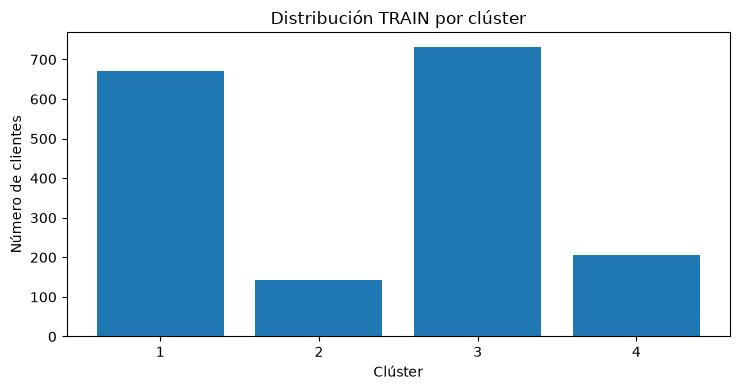

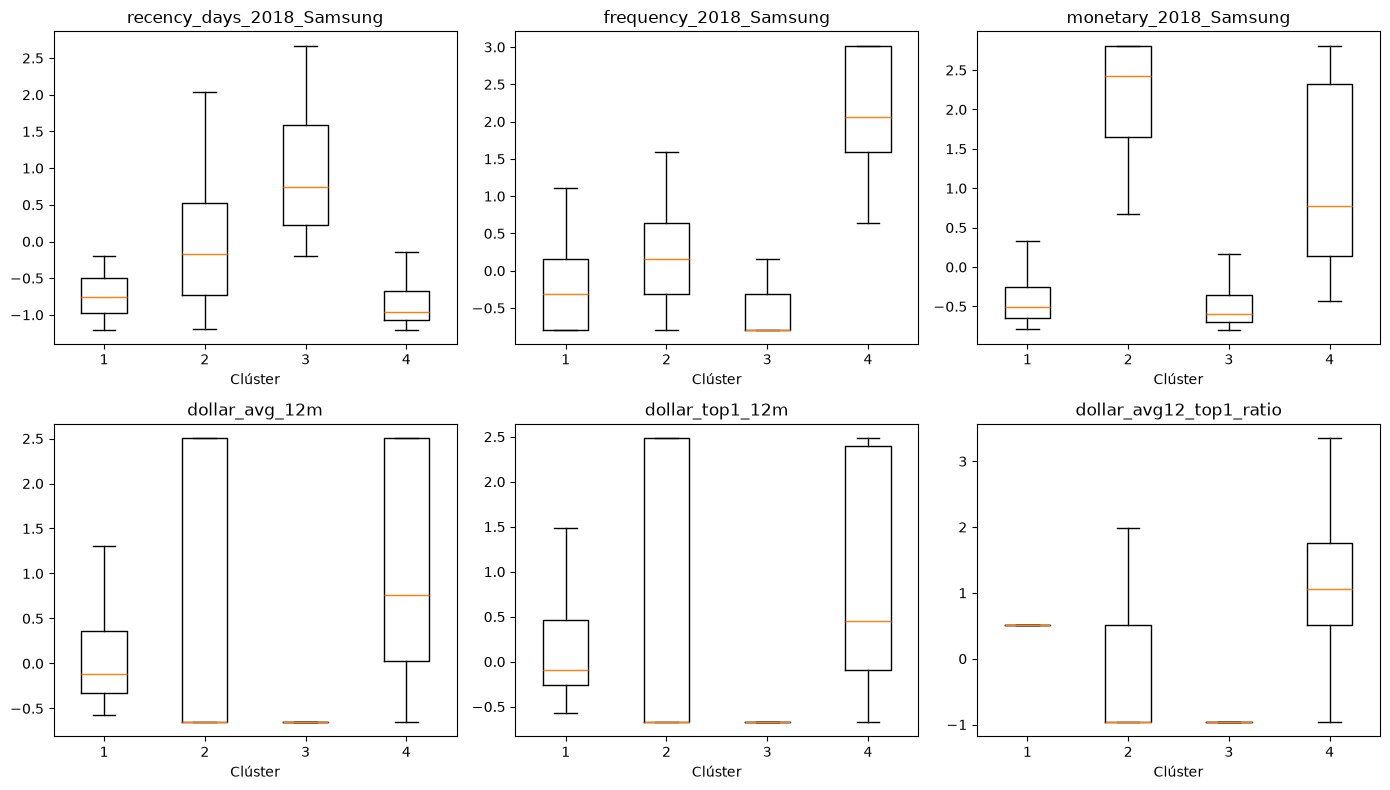

In [11]:
tamano_clusters = (
    clientes_W.groupby("cluster", sort=True).size()
    .rename("n_clientes").reset_index()
)
tamano_clusters["porcentaje_train"] = 100 * tamano_clusters.n_clientes / len(clientes_W)

perfil = clientes_W.groupby("cluster")[SEIS_VARIABLES].agg(
    ["mean", "median", "std", "min", "max", lambda s: s.quantile(.25), lambda s: s.quantile(.75)]
)
perfil.columns = [
    f"{variable}_{ {'<lambda_0>': 'q25', '<lambda_1>': 'q75'}.get(stat, stat)}"
    for variable, stat in perfil.columns
]
perfil = perfil.reset_index().merge(tamano_clusters, on="cluster", validate="one_to_one")

# Tabla resumida, práctica para la tesis: mediana de cada variable por segmento
perfil_medianas = clientes_W.groupby("cluster")[SEIS_VARIABLES].median().reset_index()
perfil_medianas = perfil_medianas.merge(tamano_clusters, on="cluster", validate="one_to_one")

# Caracterización ampliada: TODAS las columnas numéricas de W (no intervienen
# en el ajuste salvo las 3/4/6 explícitamente incluidas en CONFIGURACIONES)
TODAS_NUMERICAS_W = [c for c in df.columns if c != "response_id" and pd.api.types.is_numeric_dtype(df[c])]
perfil_completo_medianas = clientes_W.groupby("cluster")[TODAS_NUMERICAS_W].median().reset_index()
perfil_completo_medianas = perfil_completo_medianas.merge(tamano_clusters, on="cluster", validate="one_to_one")

# Centros en unidades originales de W (deshace estandarización de TRAIN de esta configuración)
params_final = parametros_escalado.loc[parametros_escalado.configuracion == CONFIG_FINAL]
medias = params_final.media_train.to_numpy(dtype=float)
desv = params_final.sd_train_ddof1.to_numpy(dtype=float)
centroides_W = pd.DataFrame(
    modelo_final.cluster_centers_ * desv + medias,
    columns=CONFIGURACIONES[CONFIG_FINAL]
)
centroides_W.insert(0, "cluster", np.arange(1, K_FINAL + 1))

print("Tamaños de clúster:")
display(tamano_clusters.round(2))
print("Medianas de variables transaccionales por grupo:")
display(perfil_medianas.round(3))
print("Centroides en escala de W (preselección Pogit):")
display(centroides_W.round(3))

# Gráficos: tamaño de segmentos y distribución de las seis variables
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(tamano_clusters.cluster.astype(str), tamano_clusters.n_clientes)
ax.set(xlabel="Clúster", ylabel="Número de clientes", title="Distribución TRAIN por clúster")
fig.tight_layout()
fig.savefig(SALIDAS / "tamano_clusters_train.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, variable in zip(axs.flat, SEIS_VARIABLES):
    listas = [clientes_W.loc[clientes_W.cluster == k, variable].to_numpy()
              for k in range(1, K_FINAL + 1)]
    ax.boxplot(listas, showfliers=False)
    ax.set_xticks(range(1, K_FINAL + 1))
    ax.set(xlabel="Clúster", title=variable)
fig.tight_layout()
fig.savefig(SALIDAS / "boxplots_seis_variables_train.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Exportar resultados reproducibles

Se exportan un archivo mínimo `response_id`–`cluster`, una tabla de clientes con todas las variables W, perfiles (seis variables y perfil ampliado de todas las columnas numéricas W), métricas exactas del modelo seleccionado y centroides. También quedan en la misma carpeta las métricas y estabilidad de las secciones anteriores. No se exportan datos de encuestas ni de TEST.

In [12]:
clientes_clusters.to_csv(SALIDAS / f"clusters_train{TAG}.csv", index=False)
clientes_W.to_csv(SALIDAS / f"clientes_W_train_con_cluster{TAG}.csv", index=False)
tamano_clusters.to_csv(SALIDAS / "tamano_clusters_train.csv", index=False)
perfil.to_csv(SALIDAS / "perfiles_train_todas_6_W_estadisticas.csv", index=False)
perfil_medianas.to_csv(SALIDAS / "perfiles_train_medianas_W.csv", index=False)
perfil_completo_medianas.to_csv(SALIDAS / "perfiles_train_todas_columnas_W_medianas.csv", index=False)
metricas_finales.to_csv(SALIDAS / "metricas_exac_final_train.csv", index=False)
centroides_W.to_csv(SALIDAS / "centroides_W_unidades_train.csv", index=False)

# Auditoría de que se exportó exactamente la cohorte TRAIN del CSV
releido = pd.read_csv(SALIDAS / f"clusters_train{TAG}.csv", dtype={"response_id": "string"})
assert len(releido) == len(df)
assert releido.response_id.is_unique
assert set(releido.response_id) == set(df.response_id)
assert releido.cluster.between(1, K_FINAL).all()

print("Exportación completada. Carpeta:", SALIDAS.resolve())
print("Archivos generados:")
for archivo in sorted(SALIDAS.iterdir()):
    print(" -", archivo.name)

Exportación completada. Carpeta: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_kmeans_python_min80
Archivos generados:
 - auditoria_variables_W.csv
 - boxplots_seis_variables_train.png
 - centroides_W_unidades_train.csv
 - clientes_W_train_con_cluster_min80.csv
 - clusters_train_min80.csv
 - comparacion_candidatos_con_estabilidad.csv
 - correlacion_spearman.csv
 - correlacion_spearman.png
 - estabilidad_ari_jaccard_repeticiones.csv
 - estabilidad_jaccard_por_cluster.csv
 - exploracion_A_B_C_k2_k10.csv
 - grafico_calinski_harabasz.png
 - grafico_codo_A_RFM_3.png
 - grafico_codo_B_RFM_ratio_4.png
 - grafico_codo_C_W_6.png
 - grafico_davies_bouldin.png
 - grafico_min_cluster_pct.png
 - grafico_silhouette_euclidean.png
 - metricas_exac_final_train.csv
 - parametros_escalado_train.csv
 - perfiles_train_medianas_W.csv
 - perfiles_train_todas_6_W_estadisticas.csv
 - perfiles_train_todas_columnas_W_medianas.csv
 - resumen_metodo_codo.csv
 - resumen_var

## 11. Consideraciones para la tesis

1. Se trabaja con la **misma cohorte TRAIN de Pogit**, tal como fue exportada desde R, pero no se usan resultados de Pogit ni T2 como características de agrupamiento. La regla de exclusión T2 forma parte de la definición previa de la cohorte, no de las distancias K-Means.
2. La **recencia** tiene interpretación invertida: menos días implica compras más recientes. No numerar clústeres por valor comercial sin un criterio explícito.
3. Se utilizan **3, 4 y 6 variables** deliberadamente, no las 28 columnas numéricas disponibles en W. Las restantes pueden considerarse en investigaciones futuras, pero no se introducen inadvertidamente.
4. La caracterización se realiza **solo con W**. La razón para caracterizar también con seis variables cuando el ajuste usa tres o cuatro es describir patrones adicionales, evitando usar variables T2 para escoger la solución.
5. Los importes de W reflejan la **winsorización** previa: no son necesariamente transacciones crudas. No recalcular `dollar_avg12_top1_ratio` desde los importes winsorizados, porque su valor histórico fue calculado antes.
6. Seleccionar un modelo exige revisar **calidad interna, grupos pequeños, estabilidad por ARI y Jaccard e interpretabilidad**. La silueta sola no garantiza mejores segmentos comerciales. K=4 es una referencia, no una conclusión obligatoria.
7. **TEST es opcional** para K-Means no supervisado. Este notebook no lo lee ni lo necesita. Si se decide comprobar generalización descriptiva, se asignarán nuevos clientes a centroides entrenados exclusivamente con TRAIN y usando los parámetros de escalado guardados.
8. Las etiquetas de clúster son categorías arbitrarias. La evidencia de estabilidad por submuestreo no debe confundirse con intervalos de confianza ni con validación supervisada.

**Producto central del notebook:** `clusters_train{TAG}.csv`, con un `response_id` por cliente y su clúster asignado, apto para cruzar posteriormente con otros resultados por identificador.

## 12. Análisis de sensibilidad de la segmentación (uno o varios valores de K)

**Pregunta:** ¿Hasta qué punto la asimetría, las colas de las variables (ya winsorizadas) y la redundancia entre variables cambian los segmentos?

Este análisis **no modifica** la selección ni los resultados finales de las secciones anteriores. Trabaja con los **mismos clientes TRAIN**. El valor de K se define explícitamente en la siguiente celda de configuración, independiente de `K_FINAL`:

- Para evaluar varios valores, por ejemplo `K_SENSIBILIDAD = [2, 3, 4, 5]`.
- Para evaluar un solo valor, por ejemplo `K_SENSIBILIDAD = 4`.

Para cada K se ajustan las mismas alternativas y se calculan Silhouette, Davies–Bouldin, Calinski–Harabasz, tamaños, ARI y porcentaje de clientes cuya asignación cambia después de alinear las etiquetas.

Escenarios:
- **Referencia A/B/C:** W winsorizada en R + Z-score con `ddof=1` sobre TRAIN.
- **Asimetría:** `log1p` solo a gastos monetarios, seguido de Z-score. No transforma el ratio ni recalcula su definición.
- **Colas aún presentes:** tope adicional del **percentil 85** aplicado solo a variables monetarias, seguido de Z-score. Es una **prueba de estrés**, no el procesamiento propuesto para la tesis. No mide el efecto de la winsorización original.
- **Escala robusta:** mediana y rango intercuartílico (`RobustScaler`) en lugar de Z-score.
- **Redundancia:** comparar seis variables con cinco eliminando por separado `dollar_top1_12m` o `dollar_avg_12m`.

**Precauciones:** los valores de Silhouette entre espacios de diferente dimensionalidad no demuestran por sí solos superioridad. El ARI no es una prueba de significancia. Se comparan las alternativas **dentro de cada K**, nunca etiquetas generadas para distintos K mediante el porcentaje de reasignación.


In [13]:
from sklearn.preprocessing import RobustScaler
from scipy.stats import skew

# Diagnóstico de distribución (valores de W después de winsorización en R)
diagnostico_distribuciones = pd.DataFrame({
    "variable": SEIS_VARIABLES,
    "asimetria_Fisher_Pearson": [float(skew(df[v], bias=False)) for v in SEIS_VARIABLES],
    "porcentaje_ceros": [100 * float((df[v] == 0).mean()) for v in SEIS_VARIABLES],
    "p50": [float(df[v].quantile(.50)) for v in SEIS_VARIABLES],
    "p85": [float(df[v].quantile(.85)) for v in SEIS_VARIABLES],
    "p95": [float(df[v].quantile(.95)) for v in SEIS_VARIABLES],
    "max": [float(df[v].max()) for v in SEIS_VARIABLES],
})
print("Distribuciones de las seis variables winsorizadas:")
display(diagnostico_distribuciones.round(3))
diagnostico_distribuciones.to_csv(
    SALIDAS / "sensibilidad_diagnostico_distribuciones.csv", index=False
)

Distribuciones de las seis variables winsorizadas:


,variable,asimetria_Fisher_Pearson,porcentaje_ceros,p50,p85,p95,max
0,recency_days_2018_Samsung,0.866,0.0,-0.310,1.176,2.052,2.671
1,frequency_2018_Samsung,1.544,0.0,-0.315,1.114,2.543,3.020
2,monetary_2018_Samsung,1.721,0.0,-0.458,0.892,2.811,2.811
3,dollar_avg_12m,1.679,0.0,-0.405,0.894,2.505,2.505
4,dollar_top1_12m,1.653,0.0,-0.359,0.823,2.486,2.486
5,dollar_avg12_top1_ratio,0.649,0.0,0.510,0.738,1.779,4.605


In [14]:
# ===========================================================
# CONFIGURACIÓN: cambia SOLO esta línea para evaluar K
# ===========================================================
K_SENSIBILIDAD = [2, 3, 4, 5]  # Varios K (lista)
# K_SENSIBILIDAD = 4          # Un único K (número entero)
# K_SENSIBILIDAD = [3, 5]     # También puedes elegir una lista parcial

# Normalizar y validar la entrada (un entero o una secuencia de enteros).
if isinstance(K_SENSIBILIDAD, (int, np.integer)) and not isinstance(K_SENSIBILIDAD, (bool, np.bool_)):
    KS_A_EVALUAR = [int(K_SENSIBILIDAD)]
elif isinstance(K_SENSIBILIDAD, (list, tuple, range)) and K_SENSIBILIDAD:
    if not all(isinstance(k, (int, np.integer)) and not isinstance(k, (bool, np.bool_)) for k in K_SENSIBILIDAD):
        raise TypeError("K_SENSIBILIDAD solo admite enteros, p. ej. 4 o [2, 3, 4, 5].")
    KS_A_EVALUAR = list(dict.fromkeys(map(int, K_SENSIBILIDAD)))
else:
    raise TypeError("Usa un entero (4) o una lista no vacía de enteros ([2, 3, 4, 5]).")

if any(not 2 <= k < len(df) for k in KS_A_EVALUAR):
    raise ValueError(f"Cada K debe estar entre 2 y {len(df) - 1}.")

print("Valores de K que se evaluarán:", KS_A_EVALUAR)
print("Cantidad de clientes TRAIN:", len(df))


Valores de K que se evaluarán: [2, 3, 4, 5]
Cantidad de clientes TRAIN: 1752


In [15]:
# Comparaciones controladas de transformaciones y redundancia
from scipy.optimize import linear_sum_assignment

GASTOS_W = ["monetary_2018_Samsung", "dollar_avg_12m", "dollar_top1_12m"]

def matriz_sensibilidad(variables, procedimiento="zscore"):
    tabla = df[variables].copy()
    gastos = [v for v in GASTOS_W if v in variables]

    if procedimiento == "log1p_gastos":
        if (tabla[gastos] < 0).any().any():
            raise ValueError("log1p requiere gastos no negativos")
        tabla[gastos] = np.log1p(tabla[gastos])
    elif procedimiento == "tope_p85_gastos":
        tabla[gastos] = tabla[gastos].clip(
            upper=tabla[gastos].quantile(.85), axis=1
        )
    elif procedimiento not in ("zscore", "robusto"):
        raise ValueError(f"Procedimiento desconocido: {procedimiento}")

    X = tabla.to_numpy(dtype=float)
    if procedimiento == "robusto":
        return RobustScaler().fit_transform(X)

    medias = X.mean(axis=0)
    desvs = X.std(axis=0, ddof=1)
    if np.any(desvs <= 0):
        raise ValueError("No se puede escalar una variable constante")
    return (X - medias) / desvs


VARIABLES_SIN_TOP1 = [v for v in SEIS_VARIABLES if v != "dollar_top1_12m"]
VARIABLES_SIN_PROMEDIO = [v for v in SEIS_VARIABLES if v != "dollar_avg_12m"]

PRUEBAS_SENSIBILIDAD = [
    ("A_RFM_referencia", "A", RFM, "zscore"),
    ("B_referencia", "B", CONFIGURACIONES["B_RFM_ratio_4"], "zscore"),
    ("B_log1p_gasto", "B", CONFIGURACIONES["B_RFM_ratio_4"], "log1p_gastos"),
    ("B_tope_extra_p85", "B", CONFIGURACIONES["B_RFM_ratio_4"], "tope_p85_gastos"),
    ("B_escalado_robusto", "B", CONFIGURACIONES["B_RFM_ratio_4"], "robusto"),
    ("C_referencia", "C", SEIS_VARIABLES, "zscore"),
    ("C_log1p_gastos", "C", SEIS_VARIABLES, "log1p_gastos"),
    ("C_tope_extra_p85", "C", SEIS_VARIABLES, "tope_p85_gastos"),
    ("C_escalado_robusto", "C", SEIS_VARIABLES, "robusto"),
    ("C_sin_gasto_maximo", "C", VARIABLES_SIN_TOP1, "zscore"),
    ("C_sin_gasto_promedio", "C", VARIABLES_SIN_PROMEDIO, "zscore"),
]

def porcentaje_reasignados(etiquetas_base, etiquetas_alternativas):
    # Emparejar etiquetas arbitrarias para cuantificar cambios individuales.
    k = len(np.unique(etiquetas_base))
    contingencia = np.zeros((k, k), dtype=int)
    for a, b in zip(etiquetas_base, etiquetas_alternativas):
        contingencia[int(a), int(b)] += 1
    filas, columnas = linear_sum_assignment(-contingencia)
    coincidencias = int(contingencia[filas, columnas].sum())
    return 100 * (1 - coincidencias / len(etiquetas_base))


def porcentaje_reasignados(etiquetas_base, etiquetas_alternativas):
    # Emparejar etiquetas arbitrarias para cuantificar cambios individuales.
    k = len(np.unique(etiquetas_base))
    contingencia = np.zeros((k, k), dtype=int)
    for a, b in zip(etiquetas_base, etiquetas_alternativas):
        contingencia[int(a), int(b)] += 1
    filas, columnas = linear_sum_assignment(-contingencia)
    coincidencias = int(contingencia[filas, columnas].sum())
    return 100 * (1 - coincidencias / len(etiquetas_base))


# Preparar las matrices una sola vez: no dependen de K.
matrices_sensibilidad = {
    nombre: matriz_sensibilidad(variables, procedimiento)
    for nombre, _, variables, procedimiento in PRUEBAS_SENSIBILIDAD
}

resultados_por_k = []
for k_actual in KS_A_EVALUAR:
    filas = []
    etiquetas_por_escenario = {}

    for nombre, familia, variables, _ in PRUEBAS_SENSIBILIDAD:
        X = matrices_sensibilidad[nombre]
        km = KMeans(
            n_clusters=k_actual, random_state=SEMILLA,
            n_init=N_INIT, max_iter=400
        )
        etiquetas = km.fit_predict(X)
        etiquetas_por_escenario[nombre] = etiquetas
        conteos = np.bincount(etiquetas, minlength=k_actual)
        filas.append({
            "escenario": nombre,
            "familia": familia,
            "n_variables": len(variables),
            "k": k_actual,
            "silhouette": float(silhouette_score(X, etiquetas)),
            "davies_bouldin": float(davies_bouldin_score(X, etiquetas)),
            "calinski_harabasz": float(calinski_harabasz_score(X, etiquetas)),
            "n_min_cluster": int(conteos.min()),
            "n_max_cluster": int(conteos.max()),
            "tamanos_clusters": ", ".join(map(str, sorted(conteos))),
        })

    tabla_k = pd.DataFrame(filas)

    # Sensibilidad al preprocesamiento dentro de cada familia y para el MISMO K.
    for familia, referencia in [("B", "B_referencia"), ("C", "C_referencia")]:
        for indice in tabla_k.index[tabla_k.familia.eq(familia)]:
            nombre = tabla_k.at[indice, "escenario"]
            ref = etiquetas_por_escenario[referencia]
            alt = etiquetas_por_escenario[nombre]
            tabla_k.loc[indice, "ARI_vs_referencia"] = adjusted_rand_score(ref, alt)
            tabla_k.loc[indice, "porcentaje_reasignados"] = porcentaje_reasignados(ref, alt)

    # A (RFM) se contrasta con B (RFM + ratio) para el MISMO K.
    idx_a = tabla_k.index[tabla_k.escenario.eq("A_RFM_referencia")][0]
    tabla_k.loc[idx_a, "ARI_vs_referencia"] = adjusted_rand_score(
        etiquetas_por_escenario["B_referencia"],
        etiquetas_por_escenario["A_RFM_referencia"]
    )
    tabla_k.loc[idx_a, "porcentaje_reasignados"] = porcentaje_reasignados(
        etiquetas_por_escenario["B_referencia"],
        etiquetas_por_escenario["A_RFM_referencia"]
    )

    # CSV independiente por cada valor de K.
    ruta_k = SALIDAS / f"sensibilidad_kmeans_k{k_actual}.csv"
    tabla_k.to_csv(ruta_k, index=False)
    resultados_por_k.append(tabla_k)
    print(f"K={k_actual}: {len(tabla_k)} escenarios guardados en {ruta_k.name}")
    display(tabla_k.round(4))

# CSV consolidado SOLO con los K de la ejecución actual.
resumen_sensibilidad = pd.concat(resultados_por_k, ignore_index=True)
ruta_resumen = SALIDAS / "sensibilidad_kmeans_K_seleccionados.csv"
resumen_sensibilidad.to_csv(ruta_resumen, index=False)
print(f"\nAnálisis terminado: K={KS_A_EVALUAR}; {len(df)} clientes TRAIN")
print("Archivo consolidado:", ruta_resumen)


ValueError: log1p requiere gastos no negativos

### Lectura de resultados y archivos por K

La celda de configuración permite analizar un solo K (`K_SENSIBILIDAD = 4`) o varios (`K_SENSIBILIDAD = [2, 3, 4, 5]`). El notebook guarda **un CSV por K** (`sensibilidad_kmeans_k2.csv`, etc.) y un **consolidado de la ejecución actual** (`sensibilidad_kmeans_K_seleccionados.csv`). No hace falta ejecutar cuatro veces el notebook. Las matrices de entrada se calculan una sola vez y se reutilizan para cada K. Si cambias la selección, vuelve a ejecutar la celda de configuración y la de cálculos: el consolidado se reemplazará y los CSV individuales de ejecuciones anteriores se conservarán.


- Un ARI próximo a 1 y un porcentaje pequeño de clientes reasignados indican que los grupos cambian poco frente a la referencia; valores más bajos de ARI indican mayor sensibilidad.
- Compara primero las variantes **dentro de B** y **dentro de C**, siempre contra su respectiva referencia. **A** se compara contra **B** para estudiar el aporte del ratio.
- `log1p` sirve para examinar la asimetría; el tope adicional del percentil 85 sirve para estudiar sensibilidad a las colas que permanecen después de winsorizar; `RobustScaler` prueba otra manera de ponderar las distancias.
- Eliminar una variable altamente correlacionada (de C) examina si su doble ponderación de información cambia la segmentación. La diferencia de Silhouette entre 5 y 6 dimensiones solo es orientativa.
- Los resultados no constituyen pruebas de hipótesis ni muestran directamente el efecto de la winsorización hecha en R. **Para aislar ese efecto**, sería necesario exportar desde R una matriz W previa a winsorización, con los mismos `response_id`, manteniendo idéntico el resto del proceso.
- Esta sección es exploratoria. **No reemplaces automáticamente** la solución principal. Si se observa sensibilidad alta, revisa perfiles y estabilidad ARI/Jaccard de las alternativas antes de elegir una nueva especificación.